In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, recall_score,
                             precision_score, classification_report,
                             confusion_matrix)

In [ ]:
data = np.load("mfcc_features.npz")
X = data["X"]
y_labels = data["y"]
folds = data["folds"]

print("X:", X.shape, "| y:", y_labels.shape, "| folds:", folds.shape)
print("Classes:", np.unique(y_labels))

X: (2000, 40) | y: (2000,) | folds: (2000,)
Classes: ['background' 'car_horn' 'clock_alarm' 'crying_baby' 'dog'
 'door_wood_knock' 'glass_breaking' 'siren']


In [ ]:
le = LabelEncoder()
y = le.fit_transform(y_labels)

for i, name in enumerate(le.classes_):
    print(i, "=", name)

0 = background
1 = car_horn
2 = clock_alarm
3 = crying_baby
4 = dog
5 = door_wood_knock
6 = glass_breaking
7 = siren


In [ ]:
test_mask = folds == 5
X_train, y_train = X[~test_mask], y[~test_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nTrain class counts:", np.bincount(y_train))
print("Test class counts: ", np.bincount(y_test))

Train: (1600, 40) | Test: (400, 40)

Train class counts: [1376   32   32   32   32   32   32   32]
Test class counts:  [344   8   8   8   8   8   8   8]


In [ ]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
pred = dummy.predict(X_test)

print("Accuracy :", round(accuracy_score(y_test, pred), 3))
print("Macro F1 :", round(f1_score(y_test, pred, average="macro", zero_division=0), 3))
print()
print(classification_report(y_test, pred, target_names=le.classes_, zero_division=0))

Accuracy : 0.86
Macro F1 : 0.116

                 precision    recall  f1-score   support

     background       0.86      1.00      0.92       344
       car_horn       0.00      0.00      0.00         8
    clock_alarm       0.00      0.00      0.00         8
    crying_baby       0.00      0.00      0.00         8
            dog       0.00      0.00      0.00         8
door_wood_knock       0.00      0.00      0.00         8
 glass_breaking       0.00      0.00      0.00         8
          siren       0.00      0.00      0.00         8

       accuracy                           0.86       400
      macro avg       0.11      0.12      0.12       400
   weighted avg       0.74      0.86      0.80       400



In [ ]:
rf = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)
rf.fit(X_train, y_train)
print("Random Forest trained.")

Random Forest trained.


In [ ]:
pred_rf = rf.predict(X_test)

print("Accuracy :", round(accuracy_score(y_test, pred_rf), 3))
print("Macro F1 :", round(f1_score(y_test, pred_rf, average="macro", zero_division=0), 3))
print()
print(classification_report(y_test, pred_rf, target_names=le.classes_, zero_division=0))

Accuracy : 0.877
Macro F1 : 0.29

                 precision    recall  f1-score   support

     background       0.88      1.00      0.93       344
       car_horn       0.00      0.00      0.00         8
    clock_alarm       1.00      0.50      0.67         8
    crying_baby       1.00      0.12      0.22         8
            dog       0.00      0.00      0.00         8
door_wood_knock       0.75      0.38      0.50         8
 glass_breaking       0.00      0.00      0.00         8
          siren       0.00      0.00      0.00         8

       accuracy                           0.88       400
      macro avg       0.45      0.25      0.29       400
   weighted avg       0.81      0.88      0.83       400



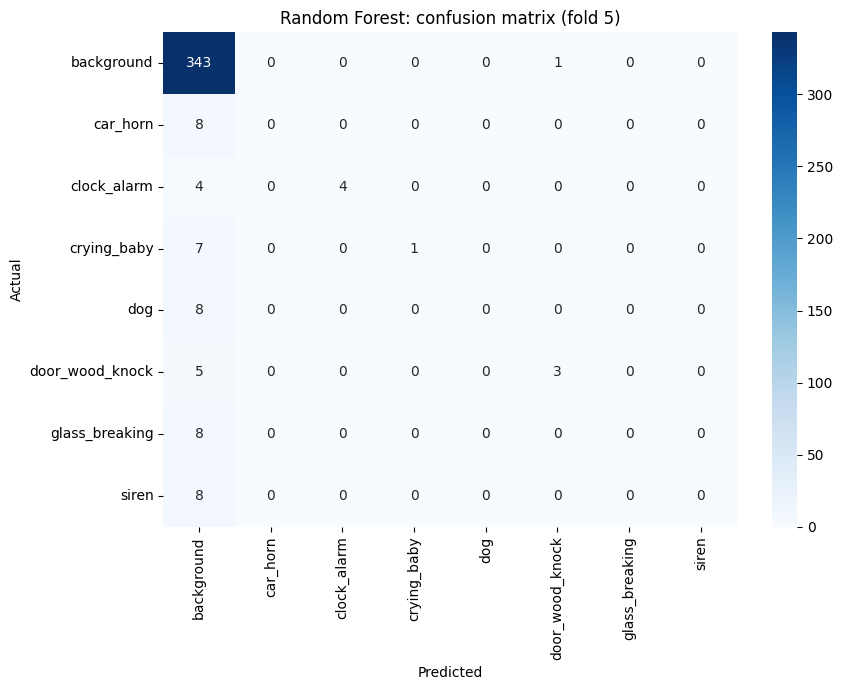

In [ ]:
cm = confusion_matrix(y_test, pred_rf)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest: confusion matrix (fold 5)")
plt.tight_layout()
plt.show()

In [ ]:
svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=10, gamma="scale",
        class_weight="balanced", random_state=42)
)
svm.fit(X_train, y_train)
print("SVM trained.")

SVM trained.


In [ ]:
pred_svm = svm.predict(X_test)

print("Accuracy :", round(accuracy_score(y_test, pred_svm), 3))
print("Macro F1 :", round(f1_score(y_test, pred_svm, average="macro", zero_division=0), 3))
print()
print(classification_report(y_test, pred_svm, target_names=le.classes_, zero_division=0))

Accuracy : 0.885
Macro F1 : 0.538

                 precision    recall  f1-score   support

     background       0.92      0.95      0.93       344
       car_horn       0.44      0.50      0.47         8
    clock_alarm       1.00      0.50      0.67         8
    crying_baby       1.00      0.25      0.40         8
            dog       0.40      0.25      0.31         8
door_wood_knock       0.67      1.00      0.80         8
 glass_breaking       0.57      1.00      0.73         8
          siren       0.00      0.00      0.00         8

       accuracy                           0.89       400
      macro avg       0.63      0.56      0.54       400
   weighted avg       0.87      0.89      0.87       400



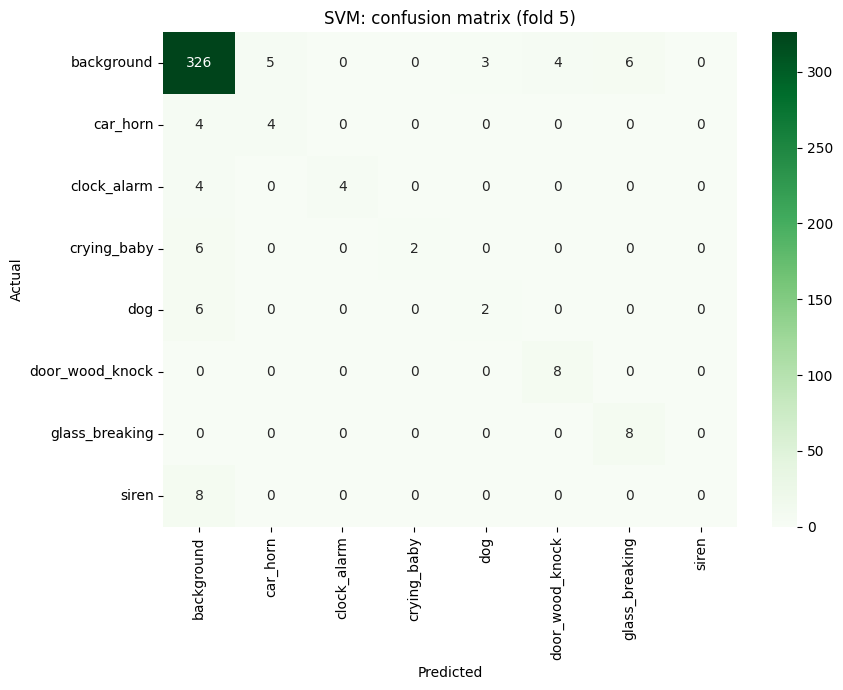

In [ ]:
cm_svm = confusion_matrix(y_test, pred_svm)

plt.figure(figsize=(9, 7))
sns.heatmap(cm_svm, annot=True, fmt="d", cmap="Greens",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM: confusion matrix (fold 5)")
plt.tight_layout()
plt.show()

In [ ]:
results = pd.DataFrame({
    "Model": ["Dumb baseline", "Random Forest", "SVM"],
    "Accuracy": [accuracy_score(y_test, p) for p in (pred, pred_rf, pred_svm)],
    "Macro F1": [f1_score(y_test, p, average="macro", zero_division=0)
                 for p in (pred, pred_rf, pred_svm)],
    "Macro recall": [recall_score(y_test, p, average="macro", zero_division=0)
                     for p in (pred, pred_rf, pred_svm)],
}).round(3)
print(results.to_string(index=False))

        Model  Accuracy  Macro F1  Macro recall
Dumb baseline     0.860     0.116         0.125
Random Forest     0.878     0.290         0.250
          SVM     0.885     0.538         0.556


In [ ]:
siren_id = list(le.classes_).index("siren")
row = cm_svm[siren_id]
for name, count in zip(le.classes_, row):
    print(f"{name:16s} {count}")

background       8
car_horn         0
clock_alarm      0
crying_baby      0
dog              0
door_wood_knock  0
glass_breaking   0
siren            0


In [ ]:
rows = []
for i, name in enumerate(le.classes_):
    rows.append({
        "class": name,
        "RF recall": recall_score(y_test, pred_rf, labels=[i], average=None)[0],
        "SVM recall": recall_score(y_test, pred_svm, labels=[i], average=None)[0],
        "SVM precision": precision_score(y_test, pred_svm, labels=[i], average=None, zero_division=0)[0],
    })
print(pd.DataFrame(rows).round(2).to_string(index=False))

          class  RF recall  SVM recall  SVM precision
     background       1.00        0.95           0.92
       car_horn       0.00        0.50           0.44
    clock_alarm       0.50        0.50           1.00
    crying_baby       0.12        0.25           1.00
            dog       0.00        0.25           0.40
door_wood_knock       0.38        1.00           0.67
 glass_breaking       0.00        1.00           0.57
          siren       0.00        0.00           0.00


In [ ]:
from sklearn.base import clone

models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1),
    "SVM": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", C=10, gamma="scale",
            class_weight="balanced", random_state=42)),
}

cv_results = {}
for name, model in models.items():
    oof_pred = np.zeros_like(y)          # out-of-fold predictions
    fold_f1 = []
    for f in [1, 2, 3, 4, 5]:
        test_idx = folds == f
        m = clone(model)
        m.fit(X[~test_idx], y[~test_idx])
        oof_pred[test_idx] = m.predict(X[test_idx])
        fold_f1.append(f1_score(y[test_idx], oof_pred[test_idx], average="macro", zero_division=0))
    cv_results[name] = (oof_pred, fold_f1)
    print(f"{name}: macro F1 per fold =", np.round(fold_f1, 3))
    print(f"   mean = {np.mean(fold_f1):.3f}, std = {np.std(fold_f1):.3f}\n")

Random Forest: macro F1 per fold = [0.276 0.229 0.306 0.374 0.29 ]
   mean = 0.295, std = 0.047

SVM: macro F1 per fold = [0.577 0.428 0.519 0.713 0.538]
   mean = 0.555, std = 0.093



In [ ]:
rows = []
for i, cls in enumerate(le.classes_):
    rows.append({
        "class": cls,
        "RF recall": recall_score(y, cv_results["Random Forest"][0], labels=[i], average=None)[0],
        "SVM recall": recall_score(y, cv_results["SVM"][0], labels=[i], average=None)[0],
    })
print(pd.DataFrame(rows).round(2).to_string(index=False))

          class  RF recall  SVM recall
     background       0.99        0.94
       car_horn       0.00        0.38
    clock_alarm       0.18        0.32
    crying_baby       0.30        0.42
            dog       0.00        0.45
door_wood_knock       0.30        0.88
 glass_breaking       0.12        0.82
          siren       0.08        0.30


In [ ]:
oof_svm = cv_results["SVM"][0]
cm_cv = confusion_matrix(y, oof_svm)
print(pd.DataFrame(cm_cv, index=le.classes_, columns=le.classes_).to_string())

                 background  car_horn  clock_alarm  crying_baby  dog  door_wood_knock  glass_breaking  siren
background             1616        18            1            8   14               15              48      0
car_horn                 23        15            0            0    0                0               2      0
clock_alarm              27         0           13            0    0                0               0      0
crying_baby              23         0            0           17    0                0               0      0
dog                      22         0            0            0   18                0               0      0
door_wood_knock           5         0            0            0    0               35               0      0
glass_breaking            7         0            0            0    0                0              33      0
siren                    26         0            0            1    1                0               0     12


In [ ]:
import numpy as np
import joblib, os

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline

# 1. Load features
data = np.load("mfcc_features.npz")
X = data["X"]
y_labels = data["y"]
folds = data["folds"]

# 2. Encode labels
le = LabelEncoder()
y = le.fit_transform(y_labels)

print("X:", X.shape, "| y:", y.shape, "| folds:", folds.shape)
print("Classes:", list(le.classes_))

# 3. Train final models on all 2,000 clips
final_rf = RandomForestClassifier(
    n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1
).fit(X, y)

final_svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=10, gamma="scale",
        class_weight="balanced", random_state=42)
).fit(X, y)

# 4. Save
os.makedirs("models", exist_ok=True)
joblib.dump(le, "models/label_encoder.pkl")
joblib.dump(final_rf, "models/random_forest.pkl")
joblib.dump(final_svm, "models/svm.pkl")
print("Saved:", os.listdir("models"))

X: (2000, 40) | y: (2000,) | folds: (2000,)
Classes: [np.str_('background'), np.str_('car_horn'), np.str_('clock_alarm'), np.str_('crying_baby'), np.str_('dog'), np.str_('door_wood_knock'), np.str_('glass_breaking'), np.str_('siren')]
Saved: ['svm.pkl', 'label_encoder.pkl', 'random_forest.pkl', 'mfcc_features.npz']


In [ ]:
from google.colab import files
for f in ["label_encoder.pkl", "random_forest.pkl", "svm.pkl"]:
    files.download(f"models/{f}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Phase 3 Summary: Traditional ML Baselines

- Features: 40 MFCC statistics per clip; 8 classes (7 targets + background)
- Evaluation: official 5-fold cross-validation; scaler and model fit on
  training folds only
- Dumb baseline (fold 5): accuracy 0.860, macro F1 0.116
- Random Forest (CV): macro F1 0.295 +/- 0.047
- SVM, RBF, C=10, scaled (CV): macro F1 0.555 +/- 0.093
- SVM beat the Random Forest in all 5 folds
- SVM per-class recall (CV): door_knock 0.88, glass 0.82, dog 0.45,
  crying_baby 0.42, car_horn 0.38, clock_alarm 0.32, siren 0.30
- 133 of 137 SVM errors on target sounds were called "background";
  confusion between target classes is rare
- 104 of 1,720 background clips triggered a false alert
- Single-fold results were misleading (siren 0/8 on fold 5 vs 12/40 overall)
- Limitations: C=10 untuned; mean/std MFCCs discard timing; far from
  safety-grade recall
- Next: YAMNet embeddings + small neural classifier, same folds and metrics